# Dataset 2 | Zhang 2020 — Tumor Microenvironment (GSE146771)

**Reference:** Zhang L. et al. (2020). *Single-Cell Analyses Inform Mechanisms of Myeloid-Targeted Therapies in Colon Cancer.* Cell, 181, 442–459.e29. [DOI: 10.1016/j.cell.2020.03.048](https://doi.org/10.1016/j.cell.2020.03.048)

**Overview:** Exploration of immune and non-immune cell populations, tissue distribution and MSI-associated patterns in the CRC tumor microenvironment.

| Dataset characteristics | Details |
|---|---|
| Full study | 18 patients (3 MSI-H, 15 MSS) |
| Analyzed cohort | 10 Smart-seq2 patients (2 MSI-H, 8 MSS) |
| Sequenced cells | 10,468 |
| Main analysis | 8 major cell types; descriptive subclusters |
| Tissues | Tumor, adjacent normal tissue, peripheral blood |

**Workflow:** Metadata → cell composition → gene expression → t-SNE → MSI-H/MSS statistics → future machine learning.

**Statistical analysis:** Patient-level tumor-cell percentages for eight major cell types are compared using two-sided Mann–Whitney U and Welch t-tests, with Benjamini–Hochberg (BH-FDR) correction.

**Limitations:** The analysis is restricted to Smart-seq2 data; the remaining patients were analyzed using 10x Genomics. FACS-based cell selection and the small MSI-H group limit interpretation. Published t-SNE coordinates are used for exploratory visualization.

**Scope:** All 10 Smart-seq2 patients are considered; comparisons with Zhang 2018 are performed separately.

## 1. Setup
Import libraries, define HPC folders and create the results directory before saving any figure.

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from IPython.display import display

PROJECT_DIR = Path("/cfs/earth/scratch/suereser/crc_singlecell")
DATA_DIR = PROJECT_DIR / "data"
GSE146771_DIR = DATA_DIR / "2020_GSE146771"
RESULTS_DIR = PROJECT_DIR / "results" / "GSE146771"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

META_PATH = GSE146771_DIR / "GSE146771_CRC.Leukocyte.Smart-seq2.Metadata.txt.gz"
TPM_PATH = GSE146771_DIR / "GSE146771_CRC.Leukocyte.Smart-seq2.TPM.txt.gz"

# Same plain white, grid-free layout as Zhang 2018.
sns.set_theme(style="white", context="notebook")
plt.rcParams["axes.grid"] = False
MSI_COLORS = {"MSI-H": "#4C78A8", "MSS": "#F28E2B"}
TISSUE_ORDER = ["Normal", "Peripheral Blood", "Tumor"]

print("Data folder:", GSE146771_DIR)
print("Results folder:", RESULTS_DIR)
print("Metadata available:", META_PATH.exists())

Data folder: /cfs/earth/scratch/suereser/crc_singlecell/data/2020_GSE146771
Results folder: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771
Metadata available: True


### 1.1 Reusable helper functions
Use a few shared functions to avoid repeated plotting code throughout the notebook.

In [30]:
def list_files(folder):
    for file in sorted(folder.glob("*")):
        if file.is_file():
            print(f"{file.name}  |  {file.stat().st_size / 1024**2:.2f} MB")

def count_and_percent(series, label):
    counts = series.dropna().value_counts()
    out = counts.rename_axis(label).reset_index(name="Cell_Count")
    out["Percentage"] = 100 * out["Cell_Count"] / out["Cell_Count"].sum()
    return out

def show_distribution(table, category_col, title, figsize=(8, 4), filename=None, color="#4C78A8"):
    display(table)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(table[category_col].astype(str), table["Cell_Count"], color=color)
    ax.invert_yaxis()
    right = max(table["Cell_Count"].max() * 0.29, 1)
    ax.set_xlim(0, table["Cell_Count"].max() + right)
    ax.set(xlabel="Sequenced cells", ylabel="", title=title)
    for b, n, pct in zip(bars, table["Cell_Count"], table["Percentage"]):
        ax.text(b.get_width() + max(table["Cell_Count"].max() * 0.01, 1),
                b.get_y() + b.get_height()/2, f"{n:,} ({pct:.1f}%)", va="center", fontsize=9)
    fig.tight_layout()
    if filename:
        fig.savefig(RESULTS_DIR / filename, dpi=250, bbox_inches="tight")
    plt.show()

def save_figure(fig, filename):
    path = RESULTS_DIR / filename
    fig.savefig(path, dpi=250, bbox_inches="tight")
    print("Saved:", path)

## 2. Data and metadata
The study recruited **18 unique patients**, but these were sequenced on two partly overlapping platforms. We restrict this notebook to the **ten Smart-seq2 patients** and do **not** restrict to patients shared with Zhang 2018.

### 2.1 Available files
Inspect which input files are present on the cluster.

In [31]:
if not GSE146771_DIR.is_dir():
    raise FileNotFoundError(f"GSE146771 data directory not found: {GSE146771_DIR}")
list_files(GSE146771_DIR)

GSE146771_CRC.Leukocyte.Smart-seq2.Metadata.txt.gz  |  0.78 MB
GSE146771_CRC.Leukocyte.Smart-seq2.TPM.txt.gz  |  388.21 MB


### 2.2 Load Smart-seq2 metadata and assign MSI status
Use the **ten Smart-seq2 patients listed in the paper**. The full 18-patient cohort includes one additional MSI-H patient (P0123), who appears **only in the 10x platform**, not in this Smart-seq2 metadata.

Cells: 10468 (expected Smart-seq2: 10,468)
Patients: 10
Major types: 8
Published subclusters: 48
Columns: ['Barcode', 'CellName', 'Sample', 'Tissue', 'Platform', 'raw.nUMI', 'raw.nGene', 'filter.nUMI', 'filter.nGene', 'ribo.per', 'raw.nCD', 'raw.nTF', 'raw.nCyt', 'raw.nLR', 'Global_Cluster', 'Sub_Cluster', 'Sub_ClusterID', 'Global_tSNE_1', 'Global_tSNE_2', 'Sub_tSNE_1', 'Sub_tSNE_2', 'integrated.Global_tSNE_1', 'integrated.Global_tSNE_2', 'MSI_Status']


,Barcode,CellName,Sample,Tissue,Platform,raw.nUMI,raw.nGene,filter.nUMI,filter.nGene,ribo.per,...,Global_Cluster,Sub_Cluster,Sub_ClusterID,Global_tSNE_1,Global_tSNE_2,Sub_tSNE_1,Sub_tSNE_2,integrated.Global_tSNE_1,integrated.Global_tSNE_2,MSI_Status
0,TCD45n-101-20180104,N_T_P0104_00001,P0104,Tumor,Smart-seq2,361999.1204,1391,149874.8968,1245,0.003445,...,Epithelial cell,hE06_UnIdent,hE06,-14.765383,34.427211,8.846055,12.177889,29.262951,-17.992092,MSS
1,TCD45n-10-20180104,N_T_P0104_00002,P0104,Tumor,Smart-seq2,528956.2216,3498,379406.2269,3081,0.001964,...,Epithelial cell,hE02_Enterocyte-GUCA2B,hE02,2.106840,32.018599,-5.121409,19.143110,31.023631,-21.388089,MSS
2,TCD45n-105-20180104,N_T_P0104_00003,P0104,Tumor,Smart-seq2,393885.6709,1831,153265.5659,1602,0.006838,...,Epithelial cell,hE02_Enterocyte-GUCA2B,hE02,-11.123330,30.973032,1.468617,17.171193,30.224962,-19.145937,MSS
3,TCD45n-107-20180104,N_T_P0104_00004,P0104,Tumor,Smart-seq2,633193.9909,1753,426985.2652,1559,0.000738,...,Epithelial cell,hE02_Enterocyte-GUCA2B,hE02,-14.009335,31.040385,-0.626185,16.515109,30.202433,-19.185950,MSS
4,TCD45n-108-20180104,N_T_P0104_00005,P0104,Tumor,Smart-seq2,511993.8998,5127,328379.3209,4369,0.025553,...,Epithelial cell,hE03_Goblet-SPINK4,hE03,-1.466837,36.112234,1.219953,4.973067,26.183327,-15.175587,MSS


Full study: 18 patients (3 MSI-H, 15 MSS).
Smart-seq2 subset: 10 patients (2 MSI-H, 8 MSS).
10x subset: 10 patients (1 MSI-H, 9 MSS).
Profiled on both platforms: ['P0104', 'P0305']
MSI-H P0123 is 10x-only and is not present in Smart-seq2 metadata.
Patients by MSI status (Smart-seq2 only):


,Sample,MSI_Status
0,P0104,MSS
189,P0305,MSS
456,P0309,MSS
1643,P0411,MSS
2569,P0413,MSI-H
3938,P0720,MSS
4433,P0728,MSS
5219,P0825,MSI-H
7364,P1212,MSS
8829,P1228,MSS


,MSI_Status,Cell_Count,Percentage
0,MSS,8,80.0
1,MSI-H,2,20.0


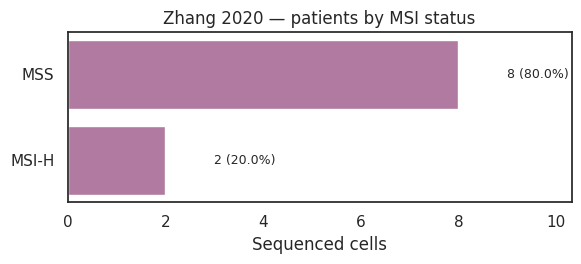

In [32]:
meta_2020 = pd.read_csv(META_PATH, sep="\t", compression="infer", low_memory=False)
meta_2020.columns = meta_2020.columns.str.strip()
required = {"Sample", "Tissue", "Global_Cluster", "Sub_Cluster",
            "Global_tSNE_1", "Global_tSNE_2"}
missing = required - set(meta_2020.columns)
if missing:
    raise ValueError(f"Missing published metadata columns: {sorted(missing)}")

meta_2020["Sample"] = meta_2020["Sample"].astype(str).str.strip()
raw_tissue = meta_2020["Tissue"].astype(str).str.strip().str.lower()
tissue_lookup = {
    "n": "Normal", "normal": "Normal", "normal tissue": "Normal", "adjacent normal": "Normal",
    "p": "Peripheral Blood", "blood": "Peripheral Blood", "peripheral blood": "Peripheral Blood",
    "pbmc": "Peripheral Blood", "peripheral blood mononuclear cells": "Peripheral Blood",
    "t": "Tumor", "tumor": "Tumor", "tumour": "Tumor", "tumor tissue": "Tumor", "tumour tissue": "Tumor",
}
meta_2020["Tissue"] = raw_tissue.map(tissue_lookup)
if meta_2020["Tissue"].isna().any():
    raise ValueError("Unknown tissue labels: " + str(sorted(raw_tissue[meta_2020["Tissue"].isna()].unique())))

# Platform-specific patient sets verified in Zhang et al. (2020), STAR Methods.
# Two patients (P0104, P0305) were profiled on BOTH platforms.
SMARTSEQ2_PATIENTS = {"P0104", "P0305", "P0309", "P0411", "P0720", "P0728", "P1212", "P1228", "P0413", "P0825"}
TENX_PATIENTS = {"P0104", "P0123", "P0202", "P0305", "P0323", "P0408", "P0410", "P0613", "P1025", "P1026"}
STUDY_MSI_H = {"P0123", "P0413", "P0825"}
STUDY_PATIENTS = SMARTSEQ2_PATIENTS | TENX_PATIENTS
assert len(STUDY_PATIENTS) == 18
assert len(STUDY_MSI_H) == 3
assert SMARTSEQ2_PATIENTS & TENX_PATIENTS == {"P0104", "P0305"}

# Only Smart-seq2 patients can be analyzed from META_PATH.
MSI_H_2020 = SMARTSEQ2_PATIENTS & STUDY_MSI_H       # 2 patients
MSS_2020 = SMARTSEQ2_PATIENTS - STUDY_MSI_H         # 8 patients
MSI_MAP_2020 = {**{p: "MSI-H" for p in MSI_H_2020},
                **{p: "MSS" for p in MSS_2020}}

observed_samples = set(meta_2020["Sample"].unique())
if observed_samples != SMARTSEQ2_PATIENTS:
    raise ValueError(f"Patient mapping mismatch. Not mapped: {sorted(observed_samples-set(MSI_MAP_2020))}; "
                     f"not found in metadata: {sorted(set(MSI_MAP_2020)-observed_samples)}")
meta_2020["MSI_Status"] = meta_2020["Sample"].map(MSI_MAP_2020)
meta_2020["Global_Cluster"] = meta_2020["Global_Cluster"].astype(str).str.strip()
meta_2020["Global_tSNE_1"] = pd.to_numeric(meta_2020["Global_tSNE_1"], errors="coerce")
meta_2020["Global_tSNE_2"] = pd.to_numeric(meta_2020["Global_tSNE_2"], errors="coerce")

print("Cells:", len(meta_2020), "(expected Smart-seq2: 10,468)")
if len(meta_2020) != 10468:
    print("WARNING: Published Smart-seq2 metadata has 10,468 cells; confirm the input file.")
print("Patients:", meta_2020["Sample"].nunique())
print("Major types:", meta_2020["Global_Cluster"].nunique())
print("Published subclusters:", meta_2020["Sub_Cluster"].nunique())
print("Columns:", meta_2020.columns.tolist())
display(meta_2020.head())

patient_status_2020 = meta_2020[["Sample", "MSI_Status"]].drop_duplicates().sort_values("Sample")
print("Full study: 18 patients (3 MSI-H, 15 MSS).")
print("Smart-seq2 subset: 10 patients (2 MSI-H, 8 MSS).")
print("10x subset: 10 patients (1 MSI-H, 9 MSS).")
print("Profiled on both platforms:", sorted(SMARTSEQ2_PATIENTS & TENX_PATIENTS))
print("MSI-H P0123 is 10x-only and is not present in Smart-seq2 metadata.")
print("Patients by MSI status (Smart-seq2 only):")
display(patient_status_2020)
show_distribution(count_and_percent(patient_status_2020["MSI_Status"], "MSI_Status"),
                  "MSI_Status", "Zhang 2020 — patients by MSI status", (6, 2.8),
                  "patients_msi_status.png", "#B07AA1")

### 2.3 Export clean **Smart-seq2** metadata
Save the verified Smart-seq2 MSI labels and normalized tissue names. The saved file contains ten patients only; it is **not** the full 18-patient study.

In [33]:
meta_2020.to_csv(RESULTS_DIR / "cell_metadata.csv", index=False)
print("Saved:", RESULTS_DIR / "cell_metadata.csv")

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/cell_metadata.csv


## 3. Descriptive cell distributions
As in the 2018 notebook, move from general tissue and patient counts to eight major types, subclusters and tissue composition. Figures have plain white backgrounds without grid lines. All proportions describe FACS-enriched sequenced cells, not unbiased in-vivo tissue abundance.

### 3.0 Overall tissue overview
A compact chart shows the sequenced-cell distribution between Normal, Peripheral Blood and Tumor.

,Tissue,Cell_Count,Percentage
0,Tumor,5220,49.866259
1,Peripheral Blood,2839,27.120749
2,Normal,2409,23.012992


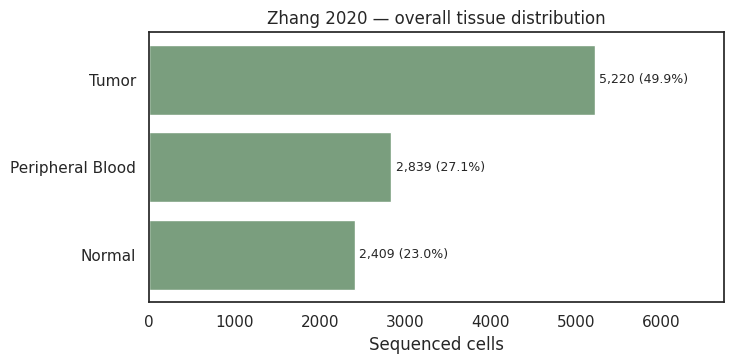

In [34]:
summary = count_and_percent(meta_2020["Tissue"], "Tissue")
show_distribution(summary, "Tissue", "Zhang 2020 — overall tissue distribution", (7.5, 3.8),
                  "overall_tissue_distribution.png", "#7A9E7E")

### 3.1 Cells per patient
Show how many sequenced cells originate from each of the ten patients.

,Patient,Cell_Count,Percentage
0,P0825,2145,20.491020
1,P1228,1639,15.657241
2,P1212,1465,13.995032
3,P0413,1369,13.077952
4,P0309,1187,11.339320
5,P0411,926,8.846007
6,P0728,786,7.508598
7,P0720,495,4.728697
8,P0305,267,2.550630
9,P0104,189,1.805502


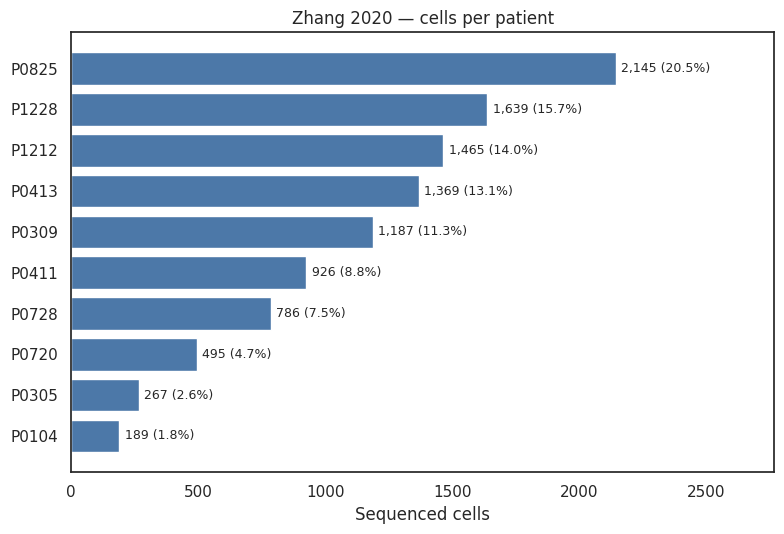

In [35]:
summary = count_and_percent(meta_2020["Sample"], "Patient")
show_distribution(summary, "Patient", "Zhang 2020 — cells per patient", (8, 5.5),
                  "cells_per_patient.png")

### 3.2 Eight major cell types
Summarize the published `Global_Cluster` categories used in the final MSI/MSS statistical comparison.

Major types: ['B cell', 'CD4 T cell', 'CD8 T cell', 'Epithelial cell', 'Fibroblast', 'ILC', 'Malignant cell', 'Myeloid cell']


,Cell_Type,Cell_Count,Percentage
0,CD4 T cell,3143,30.024838
1,CD8 T cell,2405,22.974780
2,Myeloid cell,1709,16.325946
3,B cell,991,9.466947
4,ILC,953,9.103936
5,Epithelial cell,860,8.215514
6,Malignant cell,269,2.569736
7,Fibroblast,138,1.318303


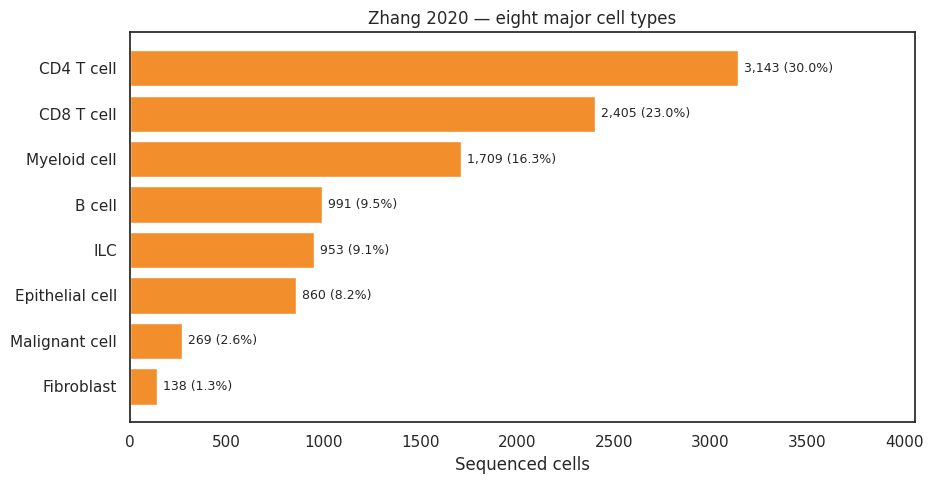

In [36]:
CELL_TYPES = sorted(meta_2020["Global_Cluster"].dropna().unique().tolist())
print("Major types:", CELL_TYPES)
if len(CELL_TYPES) != 8:
    print("WARNING: Expected eight published major types, observed", len(CELL_TYPES), "— check metadata.")
summary = count_and_percent(meta_2020["Global_Cluster"], "Cell_Type")
show_distribution(summary, "Cell_Type", "Zhang 2020 — eight major cell types", (9.5, 5),
                  "major_cell_type_distribution.png", "#F28E2B")

### 3.2.1 Twenty most frequent subclusters
    Show the 20 most abundant annotated subclusters with their observed counts and percentages; all 48 labels remain in the metadata.

Distinct published subcluster labels: 48
Top 20 subclusters out of 48 annotated labels


,Subcluster,Cell_Count,Percentage
0,hT11_CD4-CTLA4,696,6.648835
1,hT14_CD8-CX3CR1,579,5.531143
2,hT15_CD8-GZMK,570,5.445166
3,hB02_GALTB-IgA,563,5.378296
4,hM05_Mono-CD14,544,5.196790
5,hI01_NK-CD16,486,4.642721
6,hT16_CD8-CD6,434,4.145969
7,hT18_CD8-LAYN,407,3.888040
8,hT05_CD4-CXCR6,407,3.888040
9,hT01_CD4-CCR7,361,3.448605


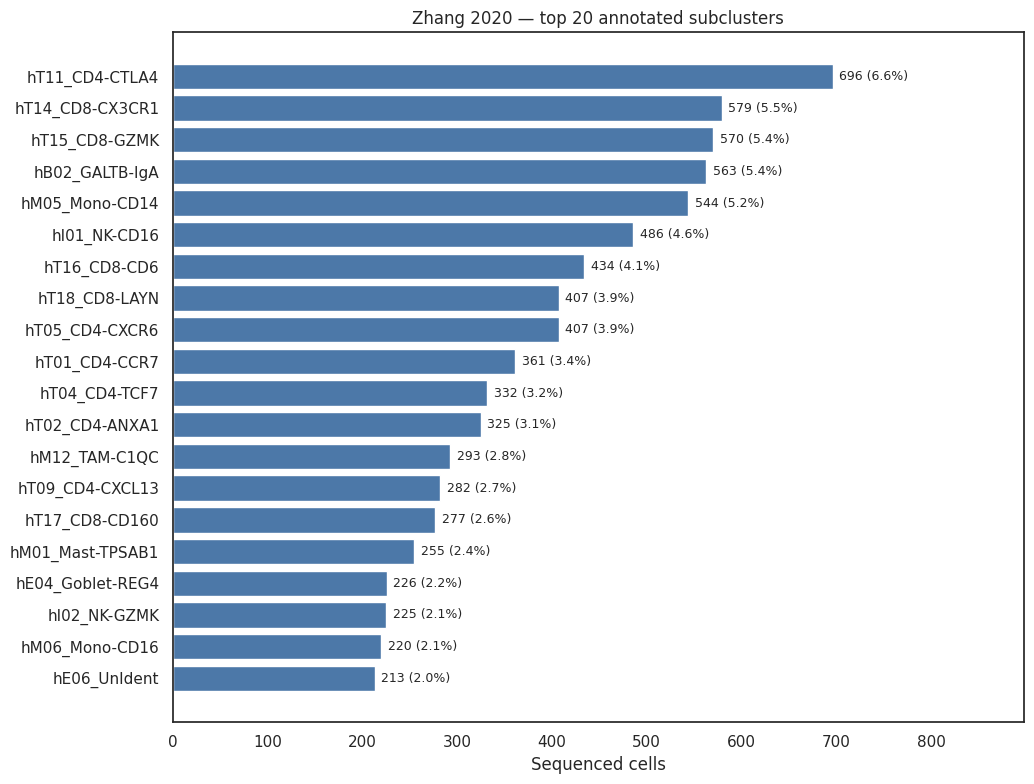

In [37]:
print("Distinct published subcluster labels:", meta_2020["Sub_Cluster"].nunique(dropna=True))
subclusters_all = count_and_percent(meta_2020["Sub_Cluster"], "Subcluster")
subclusters_top20 = subclusters_all.head(20).copy()
print("Top 20 subclusters out of", len(subclusters_all), "annotated labels")
show_distribution(
    subclusters_top20, "Subcluster",
    "Zhang 2020 — top 20 annotated subclusters",
    (10.5, 8.0), "top20_subcluster_distribution.png", "#4C78A8"
)

### 3.3 Tissue and sample annotations
Summarize tissue origin and the annotation fields that describe the published cells.

In [38]:
print("Cells by tissue and MSI status:")
display(pd.crosstab(meta_2020["Tissue"], meta_2020["MSI_Status"]).reindex(TISSUE_ORDER))
print("Cells by patient and tissue:")
display(pd.crosstab(meta_2020["Sample"], meta_2020["Tissue"]).reindex(columns=TISSUE_ORDER, fill_value=0))
if "Platform" in meta_2020:
    print("Sequencing-platform labels:")
    display(meta_2020["Platform"].value_counts())

Cells by tissue and MSI status:


MSI_Status,MSI-H,MSS
Tissue,,
Normal,870,1539
Peripheral Blood,1018,1821
Tumor,1626,3594


Cells by patient and tissue:


Tissue,Normal,Peripheral Blood,Tumor
Sample,,,
P0104,0,0,189
P0305,16,210,41
P0309,0,523,664
P0411,168,250,508
P0413,360,327,682
P0720,157,0,338
P0728,154,189,443
P0825,510,691,944
P1212,415,358,692


Sequencing-platform labels:


Platform
Smart-seq2    10468
Name: count, dtype: int64

### 3.4 Patient-level cell-type composition
Calculate descriptive cell-type percentages separately for each patient and tissue (no statistical tests yet).

In [39]:
patient_tissue_counts = pd.crosstab(
    [meta_2020["Sample"], meta_2020["Tissue"]], meta_2020["Global_Cluster"]
).reindex(columns=CELL_TYPES, fill_value=0)
patient_tissue_pct = patient_tissue_counts.div(patient_tissue_counts.sum(axis=1), axis=0).mul(100)
patient_tissue_pct.to_csv(RESULTS_DIR / "patient_tissue_percentages.csv")
print("Patient × tissue rows:", len(patient_tissue_pct))
display(patient_tissue_pct.round(1).head(12))

Patient × tissue rows: 26


Global_Cluster           B cell  CD4 T cell  CD8 T cell  Epithelial cell  \
Sample Tissue                                                              
P0104  Tumor                0.0         0.0         0.0             88.9   
P0305  Normal              31.2         0.0         0.0              0.0   
       Peripheral Blood     0.0         1.0         4.8              0.0   
       Tumor                0.0         0.0         2.4              0.0   
P0309  Peripheral Blood     0.0        27.3        20.3              0.0   
       Tumor                3.9        31.8        18.8              0.0   
P0411  Normal               0.0        31.0        68.5              0.0   
       Peripheral Blood     1.2        66.4        26.4              0.0   
       Tumor               16.7        35.0        17.9              4.3   
P0413  Normal              56.1        15.3        23.1              0.0   
       Peripheral Blood     2.1        41.6        26.3              0.0   
       Tumor                1.3        29.5        17.9             10.1   

Global_Cluster           Fibroblast   ILC  Malignant cell  Myeloid cell  
Sample Tissue                                                            
P0104  Tumor                    6.9   0.0             4.2           0.0  
P0305  Normal                   0.0  25.0             0.0          43.8  
       Peripheral Blood         0.0  28.1             0.0          66.2  
       Tumor                    0.0  17.1             0.0          80.5  
P0309  Peripheral Blood         0.0  36.1             0.0          16.3  
       Tumor                    0.0  12.7             0.0          32.8  
P0411  Normal                   0.0   0.6             0.0           0.0  
       Peripheral Blood         0.0   4.4             0.0           1.6  
       Tumor                    3.3   3.3            12.0           7.3  
P0413  Normal                   0.0   2.5             0.0           3.1  
       Peripheral Blood         0.0  15.3             0.0          14.7  
       Tumor                    0.0  24.6             7.3           9.2

### 3.5 Tissue composition overview
Plot the eight major cell-type percentages within each tissue using a stacked bar chart and heatmap.

Global_Cluster,B cell,CD4 T cell,CD8 T cell,Epithelial cell,Fibroblast,ILC,Malignant cell,Myeloid cell
Tissue,,,,,,,,
Normal,23.33,32.92,29.89,5.52,0.21,3.99,0.08,4.07
Peripheral Blood,3.06,33.96,22.12,0.18,0.00,16.03,0.00,24.66
Tumor,6.55,26.55,20.25,13.83,2.55,7.70,5.11,17.45


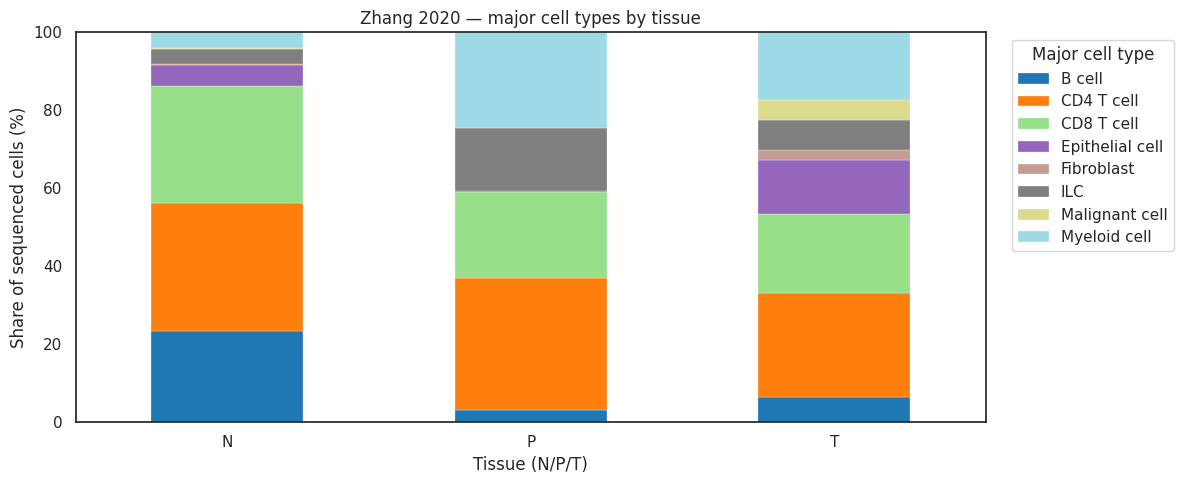

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/major_cell_types_by_tissue_heatmap.png


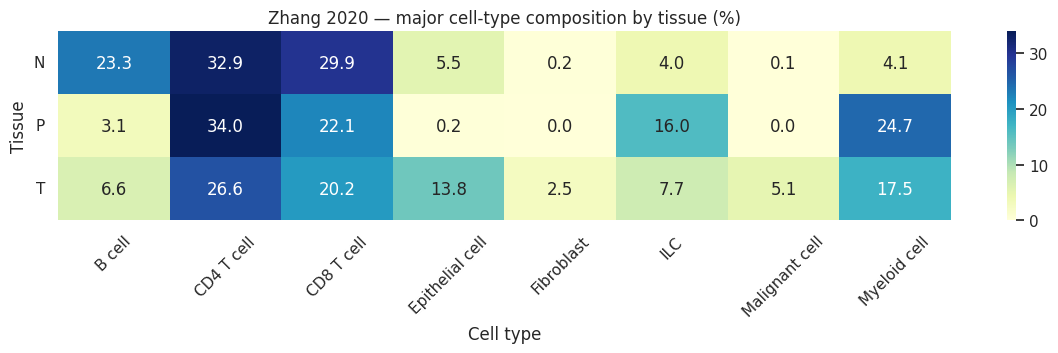

In [40]:
ct_tissue = pd.crosstab(meta_2020["Tissue"], meta_2020["Global_Cluster"])
ct_tissue = ct_tissue.reindex(index=TISSUE_ORDER, columns=CELL_TYPES, fill_value=0)
pct_tissue = ct_tissue.div(ct_tissue.sum(axis=1), axis=0).mul(100)

display(pct_tissue.round(2))

# Stacked bar plot
ax = pct_tissue.plot(
    kind="bar", stacked=True, figsize=(12, 5),
    colormap="tab20", edgecolor="white", linewidth=0.2
)

ax.set(
    title="Zhang 2020 — major cell types by tissue",
    ylabel="Share of sequenced cells (%)",
    xlabel="Tissue (N/P/T)"
)

ax.set_xticklabels(["N", "P", "T"], rotation=0)
ax.set_ylim(0, 100)
ax.grid(False)
ax.legend(title="Major cell type", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig(RESULTS_DIR / "major_cell_types_by_tissue_stacked.png", dpi=250, bbox_inches="tight")
plt.show()

# Heatmap
fig, ax = plt.subplots(figsize=(12, 3.7))

sns.heatmap(
    pct_tissue, cmap="YlGnBu",
    annot=True, fmt=".1f", linewidths=0, ax=ax
)

ax.set_yticklabels(["N", "P", "T"], rotation=0)
ax.set(
    title="Zhang 2020 — major cell-type composition by tissue (%)",
    xlabel="Cell type",
    ylabel="Tissue"
)
ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
save_figure(fig, "major_cell_types_by_tissue_heatmap.png")
plt.show()

### 3.6 Tumor cell composition by patient
Use only tumor samples for the later patient-level MSI-H/MSS comparison; this first chart is descriptive.

Tumor patients: 10 | MSI-H: 2 | MSS: 8


Global_Cluster,MSI_Status,B cell,CD4 T cell,CD8 T cell,Epithelial cell,Fibroblast,ILC,Malignant cell,Myeloid cell
Sample,,,,,,,,,
P0104,MSS,0.00,0.00,0.00,88.89,6.88,0.00,4.23,0.00
P0305,MSS,0.00,0.00,2.44,0.00,0.00,17.07,0.00,80.49
P0309,MSS,3.92,31.78,18.83,0.00,0.00,12.65,0.00,32.83
P0411,MSS,16.73,35.04,17.91,4.33,3.35,3.35,12.01,7.28
P0413,MSI-H,1.32,29.47,17.89,10.12,0.00,24.63,7.33,9.24
P0720,MSS,18.64,0.30,0.59,58.28,7.99,2.96,2.66,8.58
P0728,MSS,2.93,0.23,1.13,1.35,0.23,2.03,2.48,89.62
P0825,MSI-H,7.84,36.76,19.49,18.86,0.74,7.73,4.66,3.92
P1212,MSS,1.30,34.54,38.15,2.75,1.16,2.02,11.71,8.38


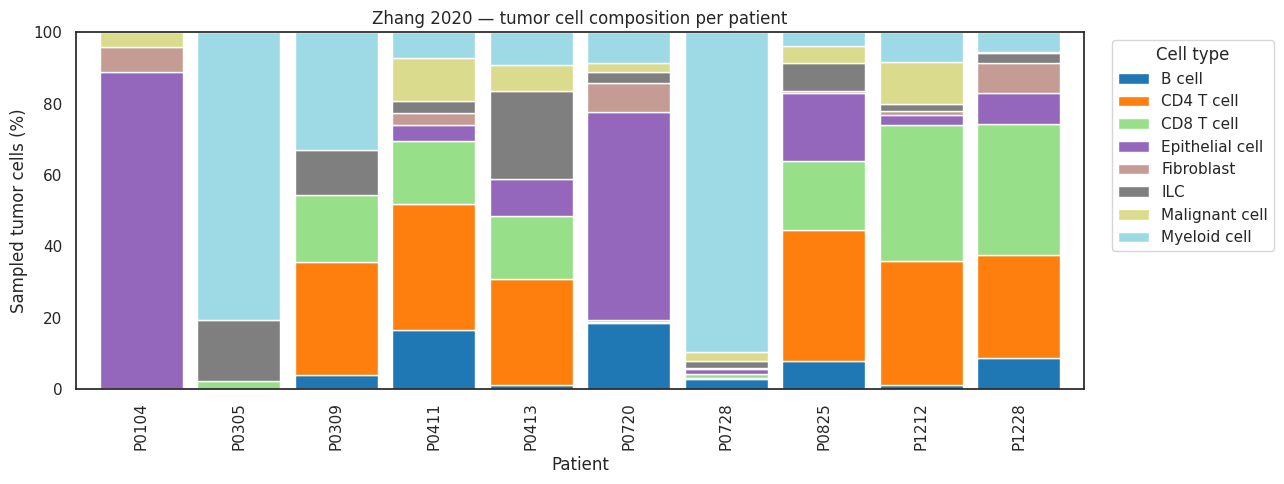

In [41]:
tumor_2020 = meta_2020.loc[meta_2020["Tissue"].eq("Tumor")].copy()
patient_tumor_counts = pd.crosstab(tumor_2020["Sample"], tumor_2020["Global_Cluster"])
patient_tumor_counts = patient_tumor_counts.reindex(columns=CELL_TYPES, fill_value=0)
patient_tumor_pct = patient_tumor_counts.div(patient_tumor_counts.sum(axis=1), axis=0).mul(100)
patient_tumor_pct.insert(0, "MSI_Status", patient_tumor_pct.index.map(MSI_MAP_2020))
patient_tumor_pct.index.name = "Sample"
patient_tumor_pct.to_csv(RESULTS_DIR / "tumor_cell_percentages_by_patient.csv", index=True)
print("Tumor patients:", len(patient_tumor_pct), "| MSI-H:", (patient_tumor_pct["MSI_Status"]=="MSI-H").sum(),
      "| MSS:", (patient_tumor_pct["MSI_Status"]=="MSS").sum())
display(patient_tumor_pct.round(2))

ax = patient_tumor_pct[CELL_TYPES].plot.bar(stacked=True, figsize=(13, 5), colormap="tab20", width=.85)
ax.set(title="Zhang 2020 — tumor cell composition per patient", ylabel="Sampled tumor cells (%)", xlabel="Patient")
ax.set_ylim(0, 100)
ax.grid(False)
ax.legend(title="Cell type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "tumor_cell_types_by_patient_stacked.png", dpi=250, bbox_inches="tight")
plt.show()

## 4. Expression matrices
Inspect the published Smart-seq2 TPM matrix without loading the entire gene × cell file into memory.

### 4.1 TPM: gene counts and metadata-to-matrix cell-ID matching
Count all genes and confirm a one-to-one match between Smart-seq2 TPM column names and the metadata `CellName` field; no full expression matrix is loaded.

In [42]:
import gzip

# Read TPM matrix preview using whitespace separation
tpm_preview = pd.read_csv(
    TPM_PATH,
    sep=r"\s+",
    nrows=5,
    compression="infer"
)

print("TPM preview (genes × cells):", tpm_preview.shape)
display(tpm_preview.iloc[:, :6])

# Count genes without loading the full matrix
with gzip.open(TPM_PATH, "rt") as f:
    next(f)  # Skip header
    gene_names = [line.split(maxsplit=1)[0] for line in f if line.strip()]

print("Gene rows:", len(gene_names))
print("Unique gene identifiers:", len(set(gene_names)))

# Match TPM cell IDs with metadata
metadata_ids = set(meta_2020["CellName"].dropna().astype(str))
tpm_ids = set(tpm_preview.columns.astype(str))
shared_ids = metadata_ids & tpm_ids

match_table = pd.DataFrame({
    "Metric": [
        "Metadata cell IDs",
        "TPM matrix cell IDs",
        "Shared IDs",
        "Metadata IDs matched (%)",
        "TPM IDs matched (%)"
    ],
    "Value": [
        len(metadata_ids),
        len(tpm_ids),
        len(shared_ids),
        round(100 * len(shared_ids) / len(metadata_ids), 2),
        round(100 * len(shared_ids) / len(tpm_ids), 2)
    ]
})

display(match_table)

assert metadata_ids == tpm_ids, "TPM and metadata IDs do not match!"
print("TPM–metadata matching successful!")

TPM preview (genes × cells): (5, 10468)


,N_T_P0104_00001,N_T_P0104_00002,N_T_P0104_00003,N_T_P0104_00004,N_T_P0104_00005,N_T_P0104_00006
A1BG,0,1.647398,0.000000,0,3.058738,0
NAT2,0,6.701314,0.000000,0,0.000000,0
ADA,0,0.000000,0.000000,0,0.000000,0
AKT3,0,0.000000,0.000000,0,0.000000,0
MED6,0,2.323996,3.634445,0,0.000000,0


Gene rows: 15179
Unique gene identifiers: 15179


,Metric,Value
0,Metadata cell IDs,10468.0
1,TPM matrix cell IDs,10468.0
2,Shared IDs,10468.0
3,Metadata IDs matched (%),100.0
4,TPM IDs matched (%),100.0


TPM–metadata matching successful!


## 5. t-SNE visualizations
Use the **published `Global_tSNE_1/2` coordinates** from the 2020 metadata consistently across all figures; do not recalculate them or mix with the 2018 embedding.

### 5.1 Check **all-cell** t-SNE coverage and coordinate source
Verify that the selected published t-SNE embedding covers all 10,468 cells before plotting. The original `Global_tSNE` pair is preferred; if it is incomplete, use the complete published integrated pair consistently instead. No downsampling, re-fitting, or mixing of coordinate systems.

In [43]:
# Check both complete published coordinate pairs; never mix coordinates from two embeddings.
COORD_OPTIONS = [
    ("Global_tSNE_1", "Global_tSNE_2", "published Smart-seq2 Global t-SNE"),
    ("integrated.Global_tSNE_1", "integrated.Global_tSNE_2", "published integrated Global t-SNE"),
]
coord_summary = []
for x, y, label in COORD_OPTIONS:
    if x in meta_2020.columns and y in meta_2020.columns:
        numeric = meta_2020[[x, y]].apply(pd.to_numeric, errors="coerce")
        good = np.isfinite(numeric.to_numpy()).all(axis=1)
        coord_summary.append({"Embedding": label, "Cells with coordinates": int(good.sum()),
                              "Total cells": len(meta_2020), "X": x, "Y": y})
display(pd.DataFrame(coord_summary)[["Embedding", "Cells with coordinates", "Total cells"]])

complete_options = [row for row in coord_summary if row["Cells with coordinates"] == len(meta_2020)]
if not complete_options:
    raise ValueError(
        "Neither published coordinate pair covers all cells. Do not silently discard cells; "
        "check the metadata and the two coordinate columns first."
    )
selected = complete_options[0]  # Prefer original Global t-SNE when complete.
TSNE_SOURCE = selected["Embedding"]
plot_data_2020 = meta_2020.copy()
plot_data_2020["tSNE_1"] = pd.to_numeric(plot_data_2020[selected["X"]])
plot_data_2020["tSNE_2"] = pd.to_numeric(plot_data_2020[selected["Y"]])
assert len(plot_data_2020) == len(meta_2020)
assert np.isfinite(plot_data_2020[["tSNE_1", "tSNE_2"]].to_numpy()).all()
print(f"Plotting ALL {len(plot_data_2020):,} Smart-seq2 cells, using {TSNE_SOURCE}.")
print("Unique coordinate pairs:", len(plot_data_2020[["tSNE_1", "tSNE_2"]].drop_duplicates()))
print("Note: overlapping dots can visually conceal cells. No cells are downsampled.")

CLUSTER_PALETTE = dict(zip(CELL_TYPES, sns.color_palette("tab10", n_colors=len(CELL_TYPES)).as_hex()))
TISSUE_PALETTE = {"Normal": "#59A14F", "Peripheral Blood": "#F28E2B", "Tumor": "#4C78A8"}

# All 48 clusters remain in metadata. Top 20 + Other is a legible exploratory view.
TOP20_SUBCLUSTERS = meta_2020["Sub_Cluster"].value_counts().head(20).index.tolist()
plot_data_2020["Subcluster_display"] = plot_data_2020["Sub_Cluster"].where(
    plot_data_2020["Sub_Cluster"].isin(TOP20_SUBCLUSTERS), "Other subclusters"
)
SUBCLUSTER_PALETTE = dict(zip(TOP20_SUBCLUSTERS, sns.color_palette("husl", n_colors=20).as_hex()))
SUBCLUSTER_PALETTE["Other subclusters"] = "#BDBDBD"

,Embedding,Cells with coordinates,Total cells
0,published Smart-seq2 Global t-SNE,10468,10468
1,published integrated Global t-SNE,10468,10468


Plotting ALL 10,468 Smart-seq2 cells, using published Smart-seq2 Global t-SNE.
Unique coordinate pairs: 10468
Note: overlapping dots can visually conceal cells. No cells are downsampled.


### 5.2 Shared t-SNE plotting functions
One legend per figure keeps the individual and multi-panel versions consistent.

In [44]:
def _color_lookup(df, color_col, palette=None):
    values = sorted(df[color_col].dropna().unique().tolist())
    if "Other subclusters" in values:
        values.remove("Other subclusters")
        values.insert(0, "Other subclusters")  # Background first, don't hide rare clusters.
    if palette is None:
        palette = dict(zip(values, sns.color_palette("husl", n_colors=len(values)).as_hex()))
    return values, palette

def tsne_single_2020(df, color_col, title, filename, palette=None, legend_title=None):
    values, colors = _color_lookup(df, color_col, palette)
    fig, ax = plt.subplots(figsize=(11.5, 7.5))
    for value in values:
        sub = df.loc[df[color_col].eq(value)]
        other = (value == "Other subclusters")
        ax.scatter(
            sub["tSNE_1"], sub["tSNE_2"], c=[colors[value]],
            s=5 if other else 13, alpha=.24 if other else .76,
            linewidths=0, rasterized=True, label=f"{value} (n={len(sub):,})"
        )
    ax.set(title=f"{title} (n={len(df):,} cells)", xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.grid(False)
    ax.legend(title=legend_title or color_col, bbox_to_anchor=(1.01, 1), loc="upper left",
              fontsize=8, markerscale=1.5, frameon=True)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()

def tsne_panels_2020(df, panel_col, color_col, title, filename, palette=None):
    if panel_col == "Tissue":
        panels = [x for x in TISSUE_ORDER if x in set(df[panel_col])]
    elif panel_col == "MSI_Status":
        panels = [x for x in ["MSI-H", "MSS"] if x in set(df[panel_col])]
    else:
        panels = sorted(df[panel_col].dropna().unique().tolist())
    values, colors = _color_lookup(df, color_col, palette)
    fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels) + 2.8, 6.2),
                             sharex=True, sharey=True, squeeze=False)
    axes = axes.ravel()
    for ax, group in zip(axes, panels):
        sub = df.loc[df[panel_col].eq(group)]
        # The gray reference contains ALL 10,468 cells from this same embedding.
        ax.scatter(df["tSNE_1"], df["tSNE_2"], s=3, color="lightgray", alpha=.28,
                   linewidths=0, rasterized=True)
        for value in values:
            selected = sub.loc[sub[color_col].eq(value)]
            if len(selected):
                other = (value == "Other subclusters")
                ax.scatter(selected["tSNE_1"], selected["tSNE_2"],
                           s=5 if other else 10, alpha=.28 if other else .85,
                           c=[colors[value]], linewidths=0, rasterized=True)
        ax.set_title(f"{group} (n={len(sub):,} cells)")
        ax.set_xlabel("t-SNE 1")
        ax.grid(False)
    axes[0].set_ylabel("t-SNE 2")
    handles = [Line2D([], [], linestyle="", marker="o", color=colors[v],
                      label=str(v), markersize=6) for v in values]
    fig.legend(handles=handles, title=color_col, loc="center left",
               bbox_to_anchor=(.99, .5), fontsize=8, frameon=True)
    fig.suptitle(title, y=.98, fontsize=14)
    fig.subplots_adjust(right=.80, wspace=.10, top=.86)
    save_figure(fig, filename)
    plt.show()

### 5.3 Single-variable t-SNE figures
Plot all cells by eight major types, tissue, MSI status, and the top 20 annotated subclusters separately. Smaller points in the former version made the same cell cloud appear sparse.

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_major_cell_types.png


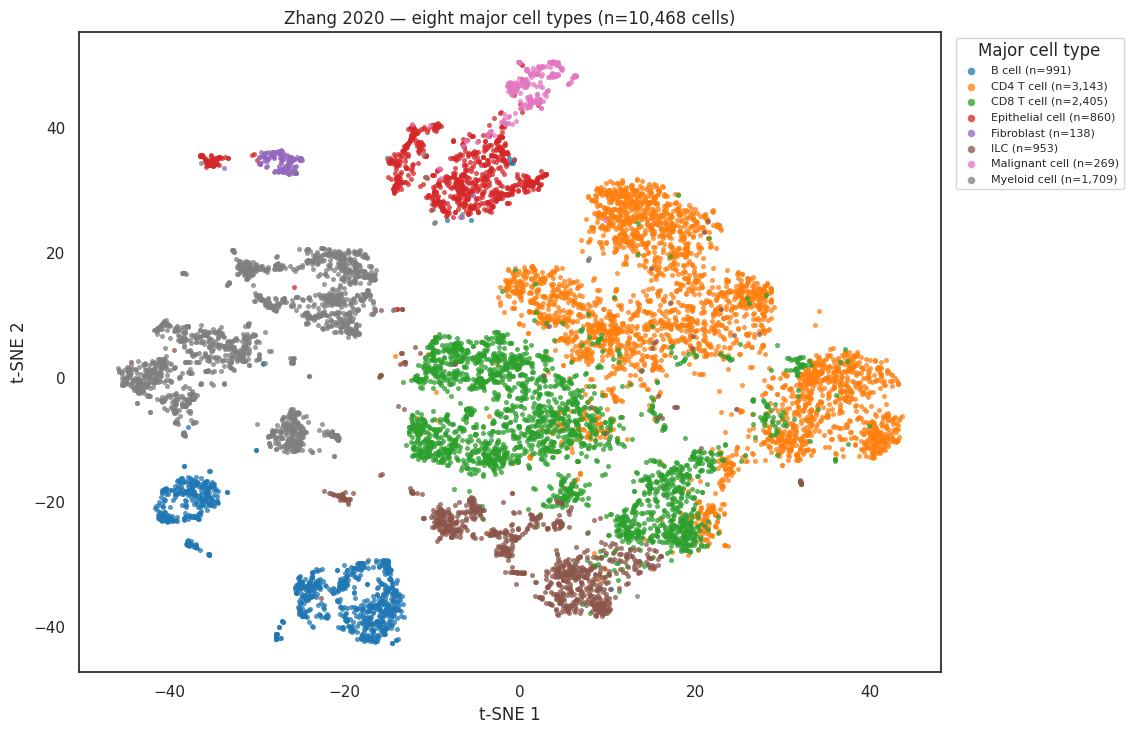

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_tissue_only.png


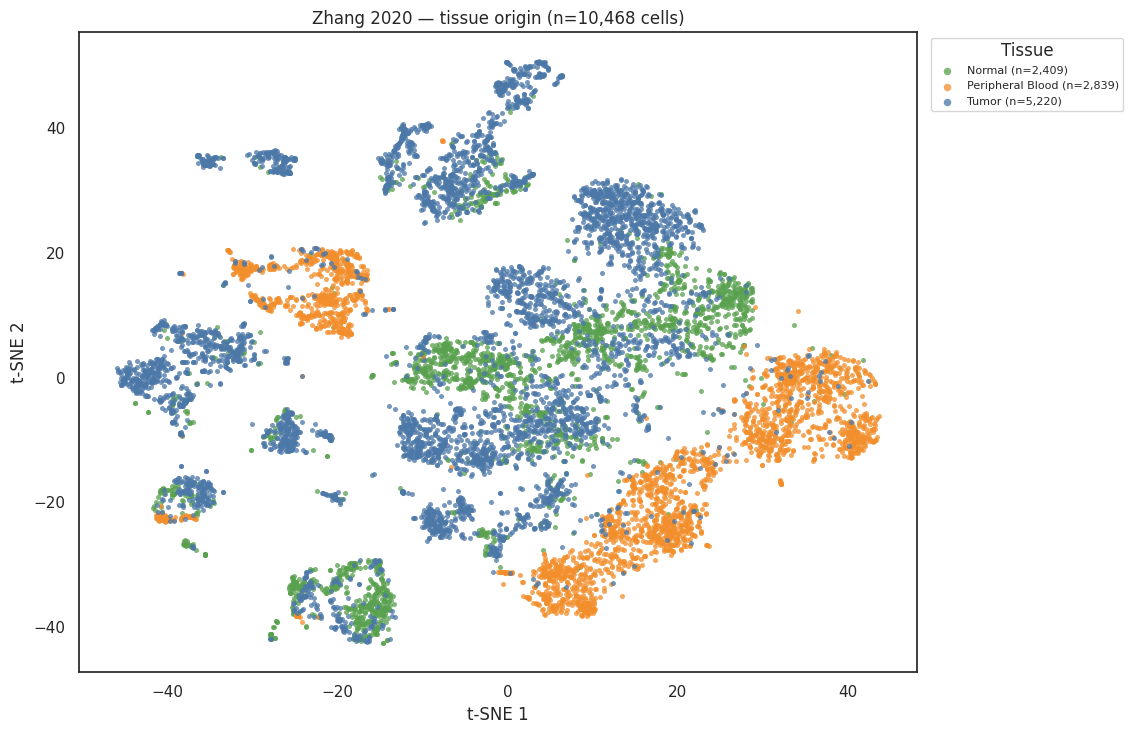

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_msi_only.png


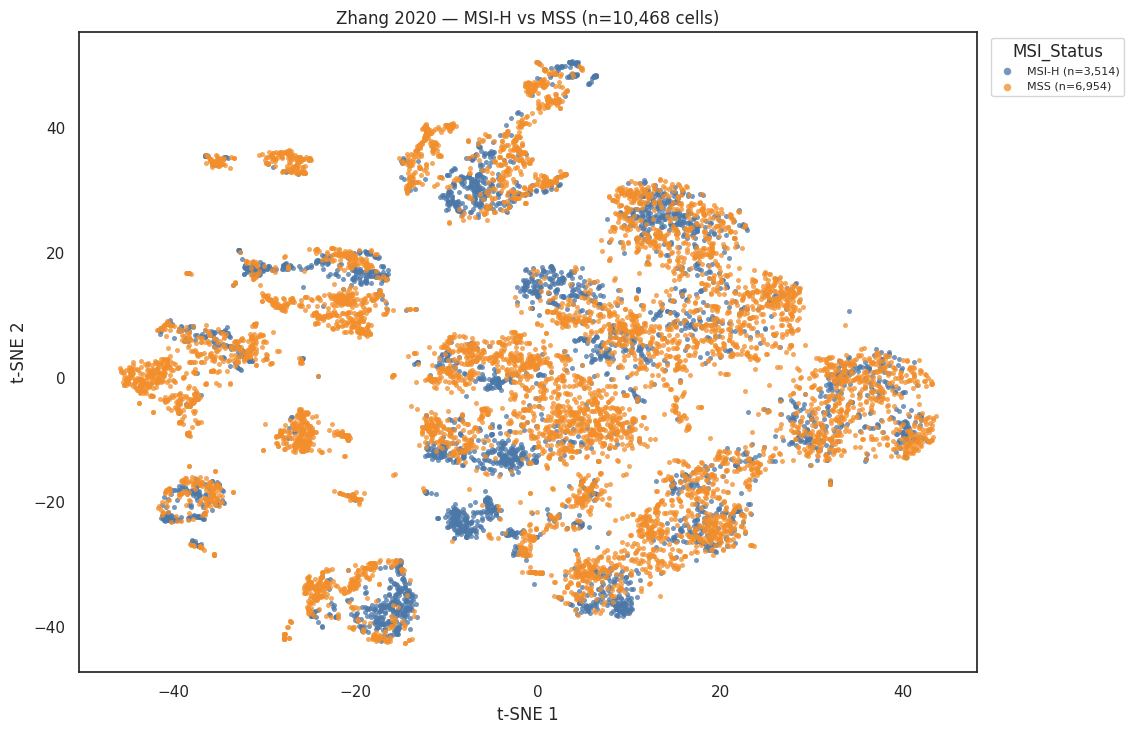

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_top20_subclusters.png


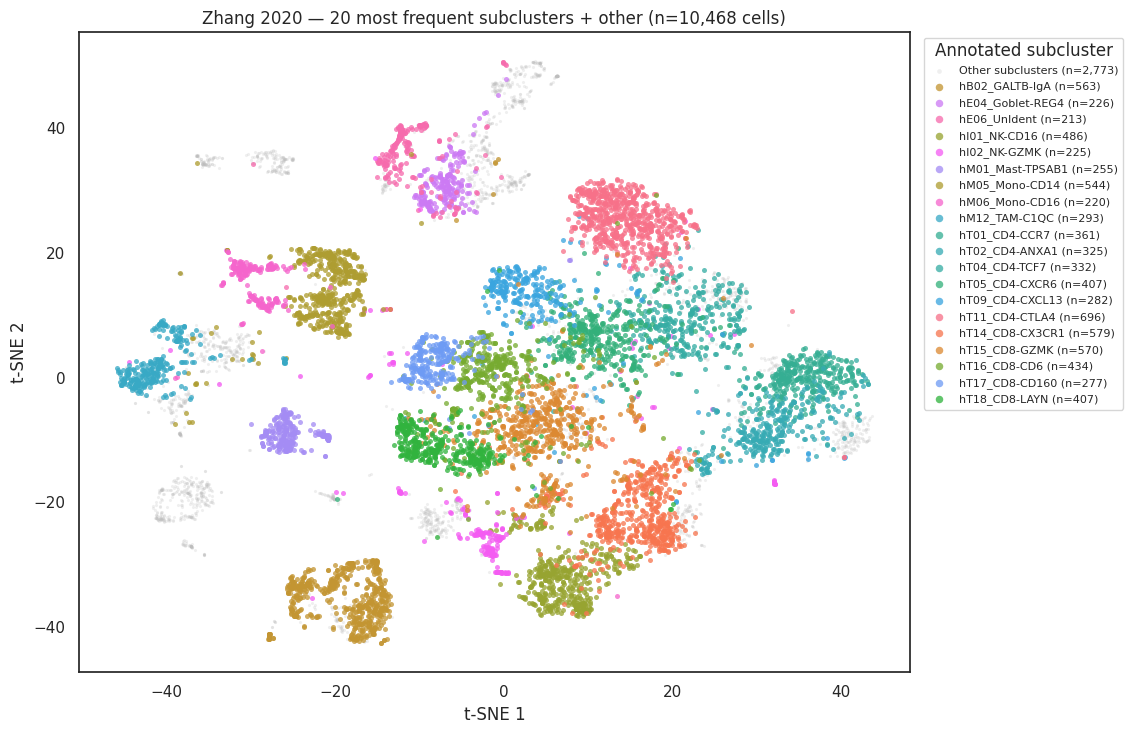

In [45]:
tsne_single_2020(plot_data_2020, "Global_Cluster", "Zhang 2020 — eight major cell types",
                 "tsne_2020_major_cell_types.png", palette=CLUSTER_PALETTE, legend_title="Major cell type")
tsne_single_2020(plot_data_2020, "Tissue", "Zhang 2020 — tissue origin",
                 "tsne_2020_tissue_only.png", palette=TISSUE_PALETTE)
tsne_single_2020(plot_data_2020, "MSI_Status", "Zhang 2020 — MSI-H vs MSS",
                 "tsne_2020_msi_only.png", palette=MSI_COLORS)

# Top 20 subclusters + gray 'Other', so the complete 10,468-cell background remains visible.
tsne_single_2020(plot_data_2020, "Subcluster_display",
                 "Zhang 2020 — 20 most frequent subclusters + other",
                 "tsne_2020_top20_subclusters.png", palette=SUBCLUSTER_PALETTE,
                 legend_title="Annotated subcluster")


### 5.4 Tissue and MSI panels (shared published embedding)
Show major types and MSI labels in separate tissue/MSI panels; top-20 subcluster panels are included for comparison with the 2018 visual sequence. Gray points show the all-cell background.

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_tissue_panels_major.png


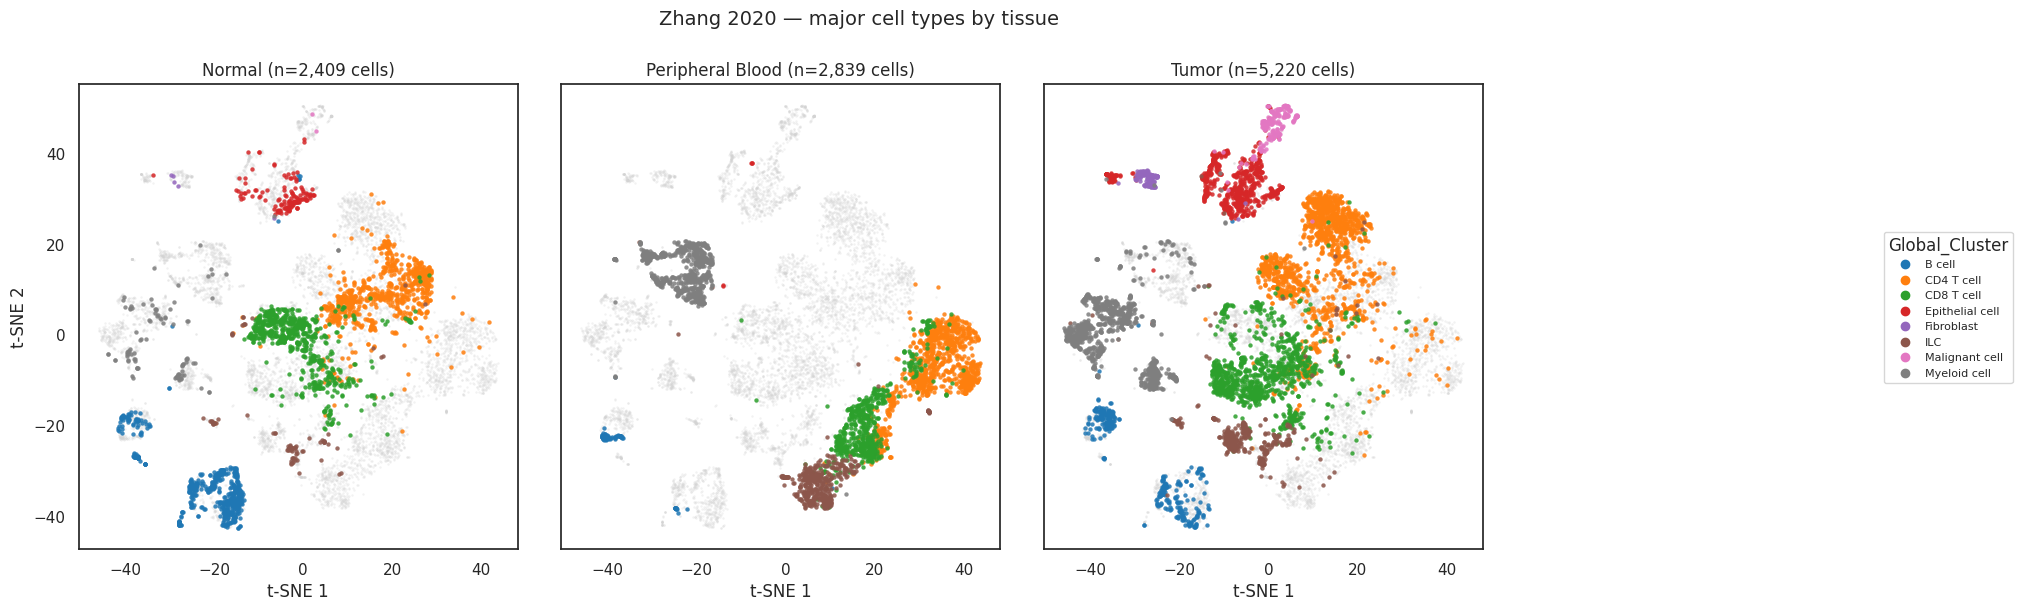

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_msi_panels_major.png


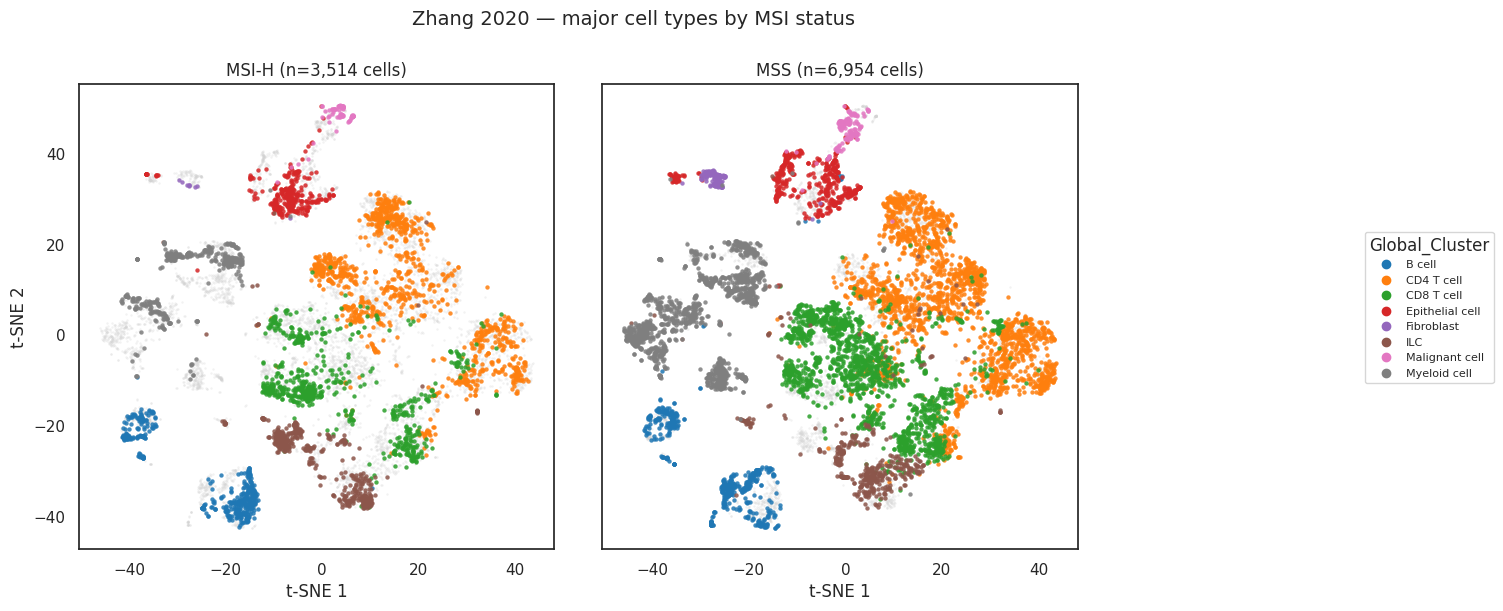

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_msi_status_by_tissue.png


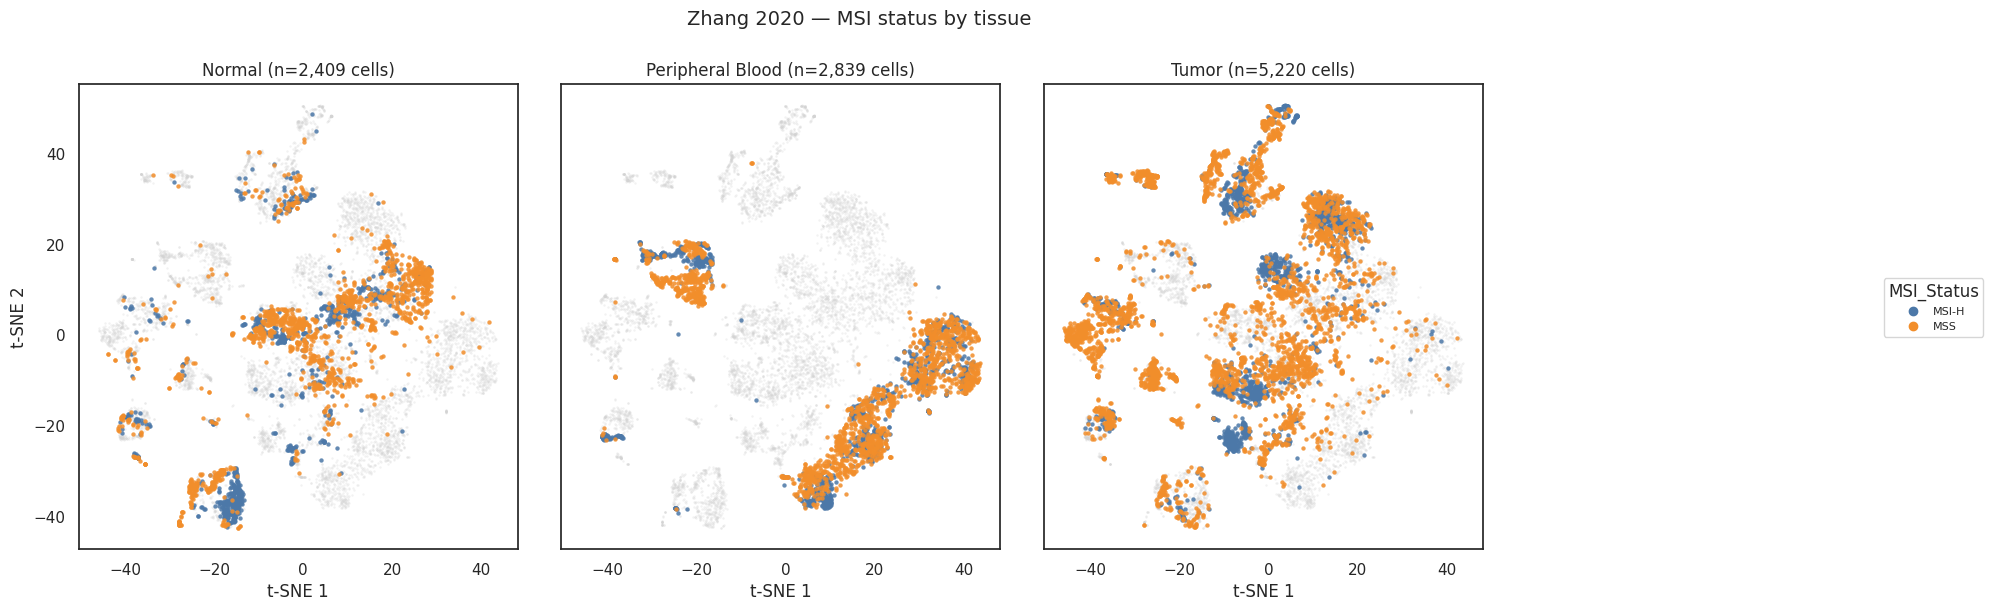

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_tissue_panels_top20_subclusters.png


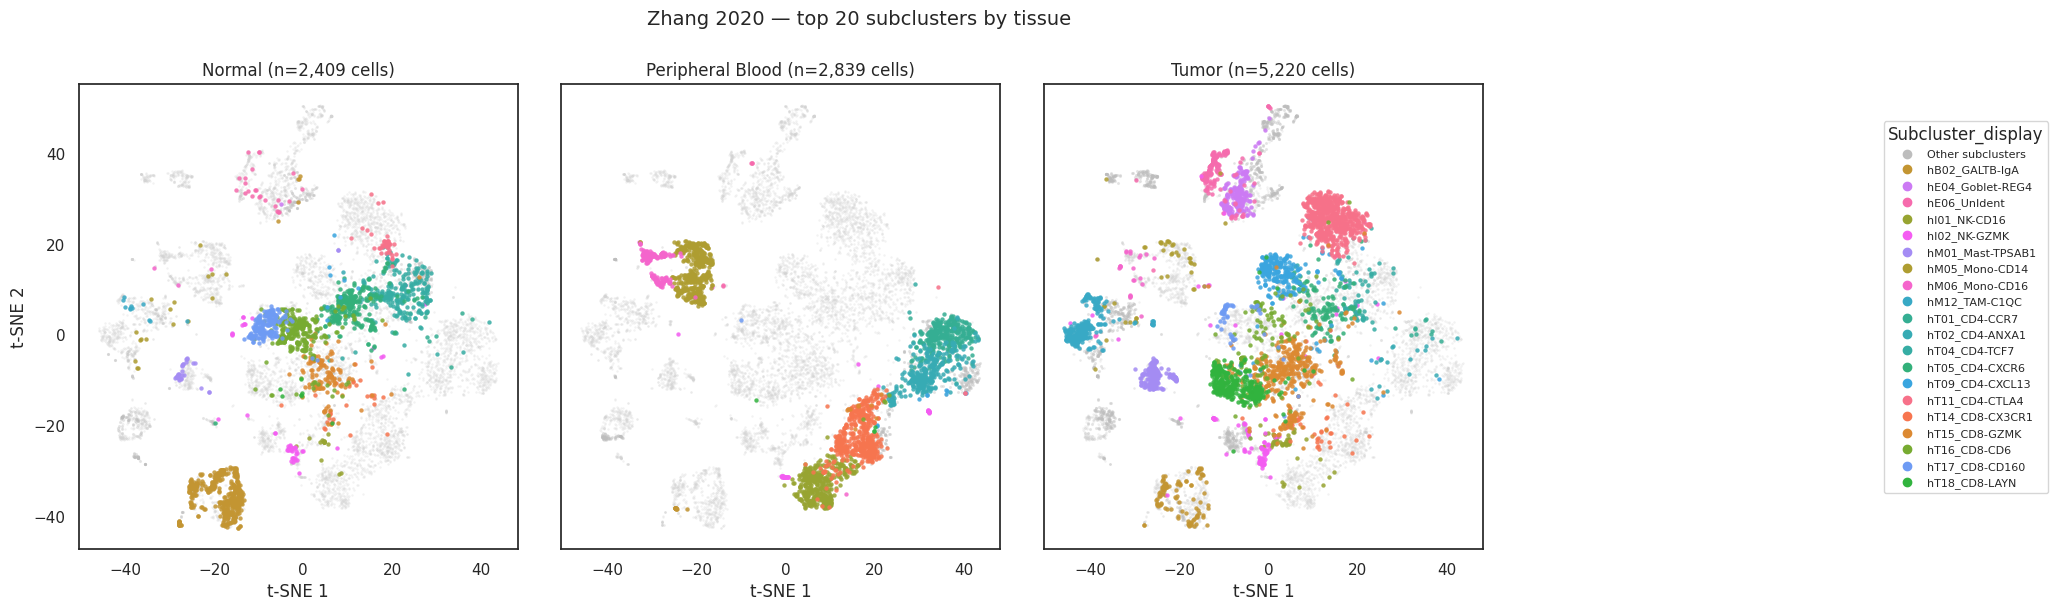

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tsne_2020_msi_panels_top20_subclusters.png


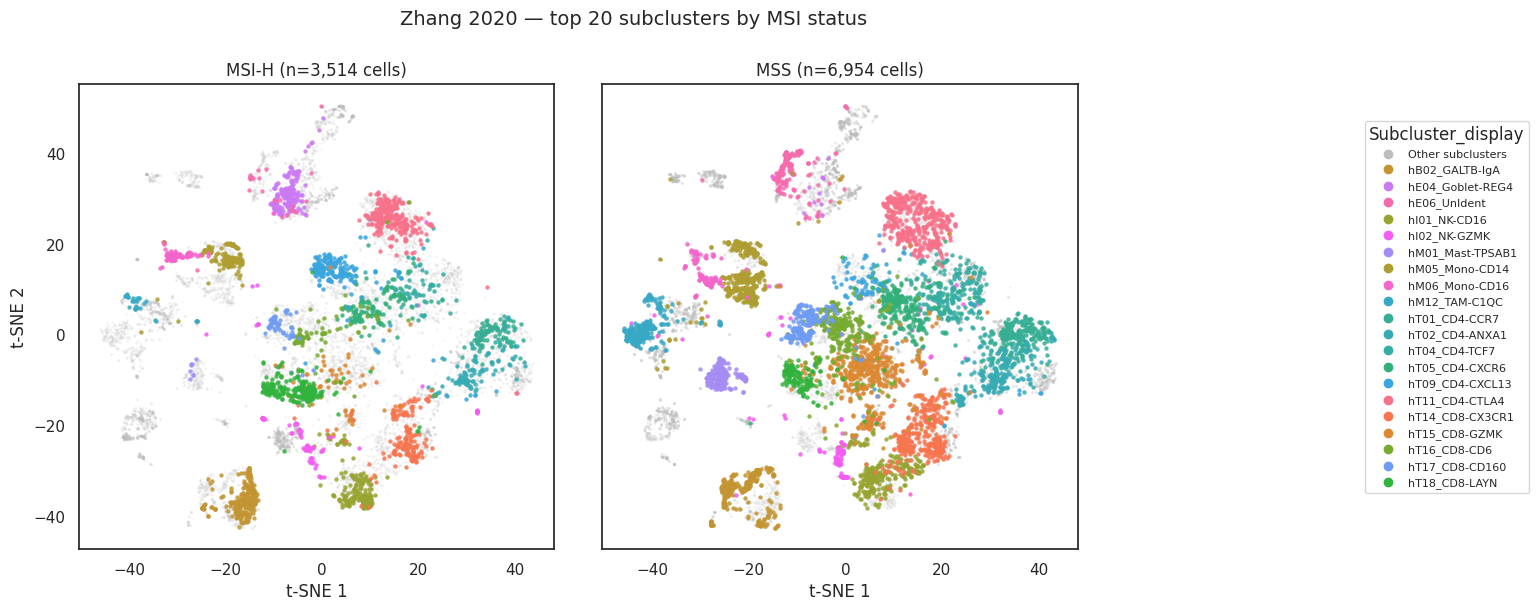

In [46]:
tsne_panels_2020(plot_data_2020, "Tissue", "Global_Cluster",
                 "Zhang 2020 — major cell types by tissue", "tsne_2020_tissue_panels_major.png",
                 palette=CLUSTER_PALETTE)
tsne_panels_2020(plot_data_2020, "MSI_Status", "Global_Cluster",
                 "Zhang 2020 — major cell types by MSI status", "tsne_2020_msi_panels_major.png",
                 palette=CLUSTER_PALETTE)
tsne_panels_2020(plot_data_2020, "Tissue", "MSI_Status",
                 "Zhang 2020 — MSI status by tissue", "tsne_2020_msi_status_by_tissue.png",
                 palette=MSI_COLORS)

# Optional more detailed tissue/MSI split with exactly the same t-SNE cells and coordinates.
tsne_panels_2020(plot_data_2020, "Tissue", "Subcluster_display",
                 "Zhang 2020 — top 20 subclusters by tissue",
                 "tsne_2020_tissue_panels_top20_subclusters.png", palette=SUBCLUSTER_PALETTE)
tsne_panels_2020(plot_data_2020, "MSI_Status", "Subcluster_display",
                 "Zhang 2020 — top 20 subclusters by MSI status",
                 "tsne_2020_msi_panels_top20_subclusters.png", palette=SUBCLUSTER_PALETTE)


## 6. Statistics — MSI-H vs MSS (Smart-seq2 tumor cell composition)
Compare the **eight major cell types** only, using patient-level tumor percentages. **Sample size: 2 MSI-H and 8 MSS** in the Smart-seq2 subset, **not** the 18-patient full cohort. Do not treat individual cells as independent patients or add P0123 without its 10x data.

### 6.1 Hypotheses, sample size and measurement
**H₀ (Mann–Whitney):** Patient-level cell-type percentage distributions are the same in MSI-H and MSS tumor samples. **H₁:** The distributions differ. **H₀ (Welch):** The two groups have equal mean percentages. **H₁:** Their means differ.

- **Unit of analysis:** One patient with a Smart-seq2 tumor sample.
- **Measurement:** Cell-type percentage = cells annotated as that major type / all annotated tumor cells sequenced from that patient × 100.
- **Actual sample groups:** **2 MSI-H (P0413, P0825) and 8 MSS**. Check the counts printed by the next cell.
- **Study-level context:** The publication reports **18 distinct patients, 3 MSI-H and 15 MSS**, but **P0123** was assayed in 10x and cannot enter this Smart-seq2 test without 10x cell annotations.
- **Main test:** Two-sided Mann–Whitney U for ranks/distributions. It avoids a normality assumption; its small-sample power remains limited. `method="auto"` uses an asymptotic approximation for tied observations.
- **Additional sensitivity check:** Two-sided Welch t-test of means; unstable with only two MSI-H patients.
- **Multiple testing:** Benjamini–Hochberg adjustment across eight cell types separately for each test. Both are exploratory.
- **Interpretation caution:** FACS-enrichment and platform-specific capture affect observed proportions. Comparing or pooling cell counts across Smart-seq2 and 10x without harmonization can mislead. Do not choose the smaller of the two tests' p-values.

In [47]:
from scipy.stats import mannwhitneyu, ttest_ind
from statsmodels.stats.multitest import multipletests

stats_pct_2020 = patient_tumor_pct.reset_index().copy()
status_counts = stats_pct_2020.groupby("MSI_Status")["Sample"].nunique().reindex(["MSI-H", "MSS"], fill_value=0)
print("Tumor patients by MSI status:")
display(status_counts)
if status_counts.min() < 2:
    raise ValueError("At least two tumor patients per MSI group are required for these comparisons.")
if set(stats_pct_2020["Sample"]) != set(MSI_MAP_2020):
    print("WARNING: Not every mapped patient has a tumor sample; only available tumor patients are tested.")

Tumor patients by MSI status:


MSI_Status
MSI-H    2
MSS      8
Name: Sample, dtype: int64

### 6.2 Calculate Mann–Whitney and Welch tests
Compute a separate p-value for each major cell type, then correct the eight p-values for each test with BH-FDR.

In [48]:
results = []
for ct in CELL_TYPES:
    msi = stats_pct_2020.loc[stats_pct_2020["MSI_Status"].eq("MSI-H"), ct].dropna().to_numpy(float)
    mss = stats_pct_2020.loc[stats_pct_2020["MSI_Status"].eq("MSS"), ct].dropna().to_numpy(float)
    # 'auto' uses exact MW for small groups without ties, asymptotic MW when ties occur.
    if np.all(msi == msi[0]) and np.all(mss == mss[0]) and msi[0] == mss[0]:
        mw_p, welch_p = 1.0, 1.0
    else:
        mw_p = float(mannwhitneyu(msi, mss, alternative="two-sided", method="auto").pvalue)
        welch_p = float(ttest_ind(msi, mss, equal_var=False, alternative="two-sided").pvalue)
    results.append({
        "Cell_Type": ct, "n_MSI_H": len(msi), "n_MSS": len(mss),
        "Median_MSI_H": np.median(msi), "Median_MSS": np.median(mss),
        "Mean_difference_pp": np.mean(msi) - np.mean(mss),
        "MW_p": mw_p, "Welch_p": welch_p
    })
stats_2020 = pd.DataFrame(results)
for p_col, q_col in [("MW_p", "MW_BH_FDR"), ("Welch_p", "Welch_BH_FDR")]:
    vals = stats_2020[p_col].to_numpy(float)
    ok = np.isfinite(vals)
    corrected = np.full(len(vals), np.nan)
    if ok.any():
        corrected[ok] = multipletests(vals[ok], method="fdr_bh")[1]
    stats_2020[q_col] = corrected

stats_2020.to_csv(RESULTS_DIR / "tumor_msi_mss_major_two_tests.csv", index=False)
display(stats_2020.round(4))

,Cell_Type,n_MSI_H,n_MSS,Median_MSI_H,Median_MSS,Mean_difference_pp,MW_p,Welch_p,MW_BH_FDR,Welch_BH_FDR
0,B cell,2,8,4.5793,3.4251,-1.9562,1.0000,0.6772,1.0000,0.6772
1,CD4 T cell,2,8,33.1153,14.6125,16.7647,0.2386,0.0524,0.5749,0.2097
2,CD8 T cell,2,8,18.6900,10.1762,4.2367,0.7111,0.4832,0.8127,0.6442
3,Epithelial cell,2,8,14.4866,3.5382,-6.0591,0.3593,0.6472,0.5749,0.6772
4,Fibroblast,2,8,0.3708,2.2513,-3.1217,0.3549,0.0515,0.5749,0.2097
5,ILC,2,8,16.1832,2.8701,10.8251,0.1778,0.4128,0.5749,0.6442
6,Malignant cell,2,8,5.9962,2.5729,1.8076,0.3593,0.4480,0.5749,0.6442
7,Myeloid cell,2,8,6.5785,8.4807,-22.4970,0.7111,0.1239,0.8127,0.3303


### 6.3 Shared plotting helper
Display one panel per cell type with patient dots, boxplots and the selected test's p-value/FDR above it.

In [49]:
def plot_msi_2020(stats_pct, stats_table, method, filename):
    if method not in {"MW", "Welch"}:
        raise ValueError("method must be 'MW' or 'Welch'")
    p_col = "MW_p" if method == "MW" else "Welch_p"
    fdr_col = "MW_BH_FDR" if method == "MW" else "Welch_BH_FDR"
    test_name = "Mann–Whitney U" if method == "MW" else "Welch t-test"

    fig, axes = plt.subplots(2, 4, figsize=(19, 9), squeeze=False)
    for ax, ct in zip(axes.ravel(), CELL_TYPES):
        tmp = stats_pct[["Sample", "MSI_Status", ct]].rename(columns={ct: "Percentage"})
        sns.boxplot(data=tmp, x="MSI_Status", y="Percentage", order=["MSI-H", "MSS"],
                    palette=MSI_COLORS, hue="MSI_Status", hue_order=["MSI-H", "MSS"],
                    dodge=False, width=.52, showfliers=False, ax=ax, legend=False)
        sns.stripplot(data=tmp, x="MSI_Status", y="Percentage", order=["MSI-H", "MSS"],
                      color="black", jitter=.10, size=5, ax=ax)
        r = stats_table.set_index("Cell_Type").loc[ct]
        ax.set_title(ct, fontsize=11, weight="bold")
        ax.text(.5, .98, f"p={r[p_col]:.3f}  |  FDR={r[fdr_col]:.3f}",
                transform=ax.transAxes, ha="center", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=.88, edgecolor="none"))
        max_v = tmp["Percentage"].max()
        ax.set_ylim(0, min(105, max(6, max_v * 1.36 + 1)))
        ax.set_xlabel("")
        ax.set_ylabel("Tumor cells (%)")
        ax.grid(False)
    fig.suptitle(f"Zhang 2020 — tumor cell composition | {test_name}\nPatient-level, two-sided; BH-adjusted p-values", fontsize=14, y=1.02)
    fig.tight_layout()
    save_figure(fig, filename)
    plt.show()

### 6.4 Eight major types — Mann–Whitney U
Use the main non-parametric comparison to assess patient-level percentage distributions.

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tumor_major_mannwhitney_pvalues.png


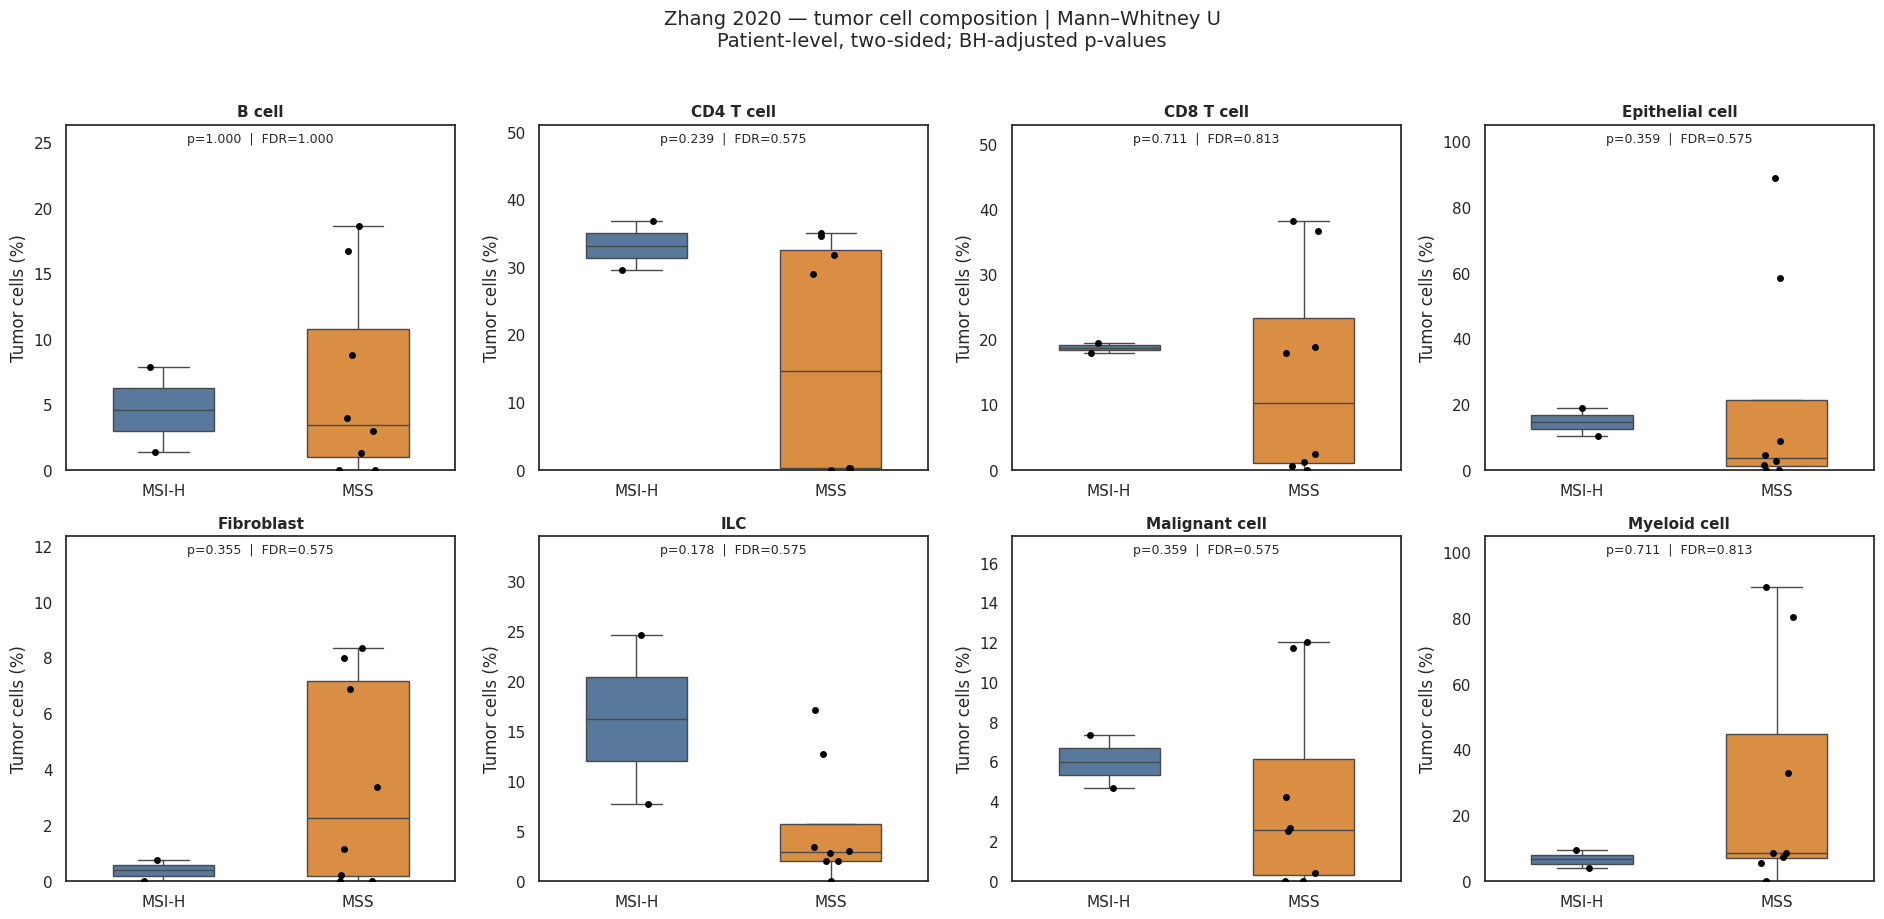

In [50]:
plot_msi_2020(stats_pct_2020, stats_2020, method="MW",
              filename="tumor_major_mannwhitney_pvalues.png")

### 6.5 Eight major types — Welch t-test
Use this as a sensitivity analysis for mean percentage differences, not a replacement for the main test.

Saved: /cfs/earth/scratch/suereser/crc_singlecell/results/GSE146771/tumor_major_welch_pvalues.png


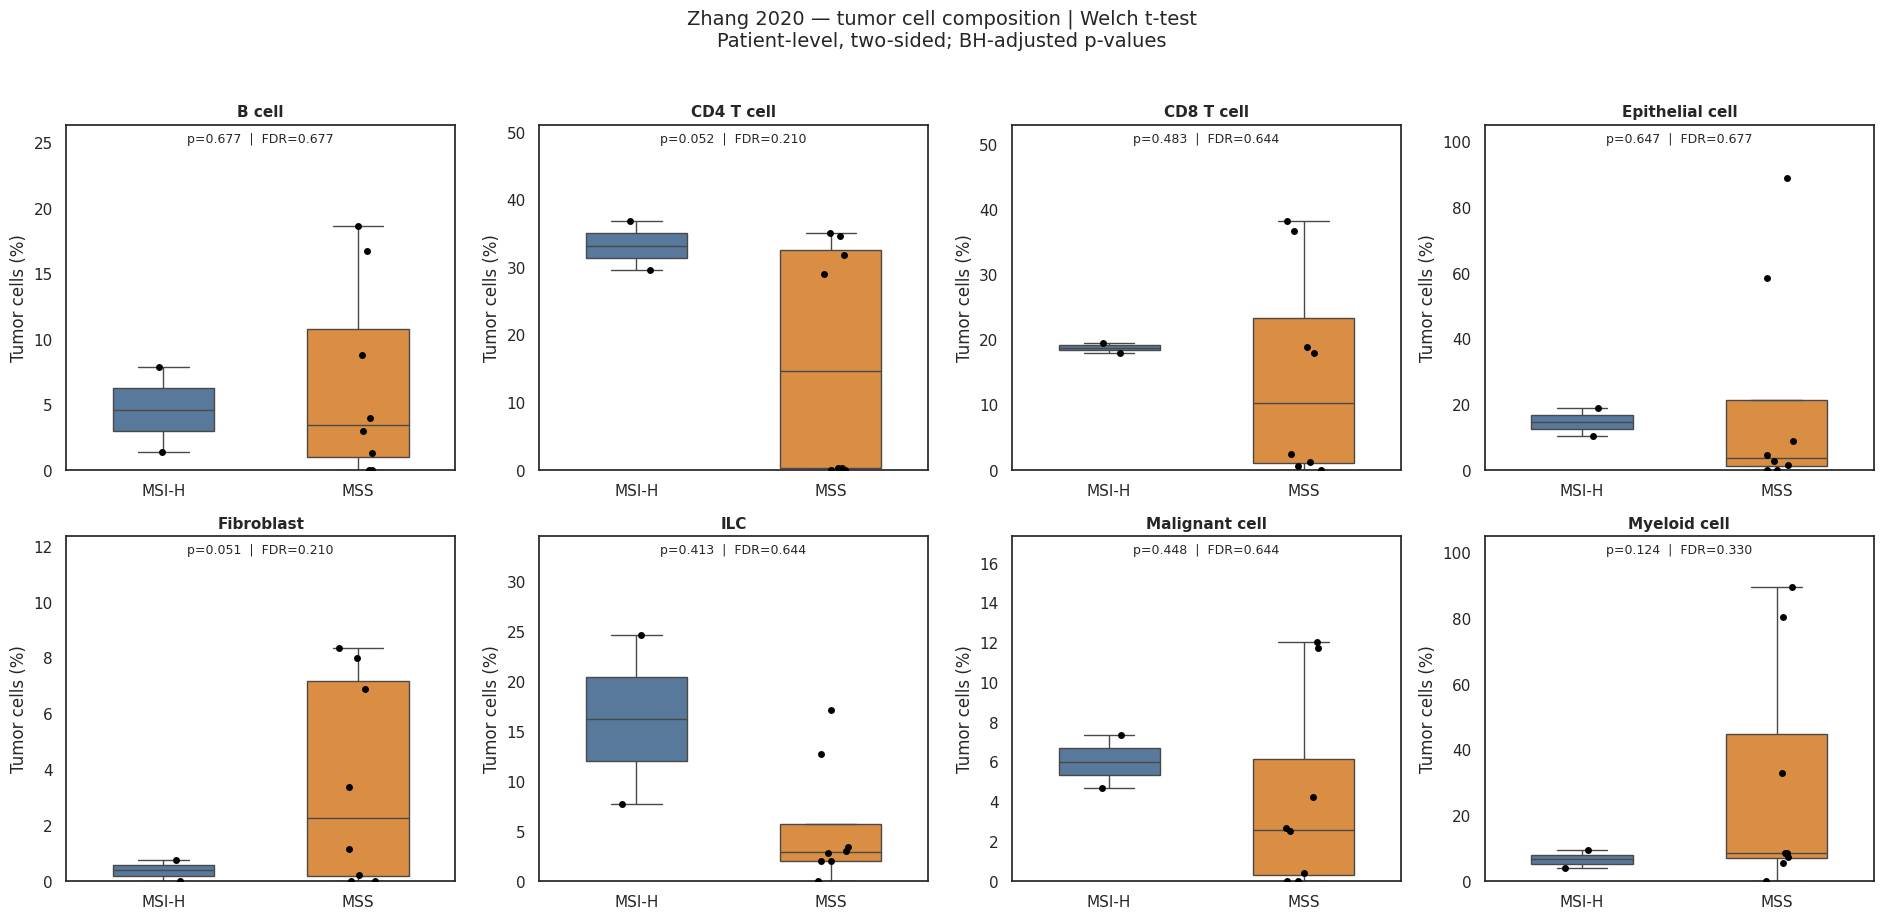

In [51]:
plot_msi_2020(stats_pct_2020, stats_2020, method="Welch",
              filename="tumor_major_welch_pvalues.png")

### 6.6 Interpretation and reporting notes
This notebook analyzes **Smart-seq2 only** (10 patients, 2 MSI-H / 8 MSS), not the full 18-patient Zhang 2020 cohort (3 MSI-H / 15 MSS). Any report figure must state the **platform, tissue, denominator, patient n, statistical test, and BH-adjusted p-value**. The two tests address related but different questions. FACS enrichment and the very small MSI-H group limit inference; lack of significance does not prove equal composition. Some Smart-seq2 T cells were also used in the 2018 work, so these datasets are **not independent validation cohorts**. To examine all 18 study patients, 10x data must also be loaded and platform differences handled explicitly.

## 7. Machine learning (future work)
...